# Klasifikasi Rekomendasi Tanaman (Crop Recommendation)

Notebook ini membangun model **klasifikasi multiclass** untuk merekomendasikan jenis tanaman yang paling cocok berdasarkan kondisi tanah dan cuaca.

**Fitur (input):** N, P, K, temperature, humidity, ph, rainfall
**Target (output):** `label` (22 jenis tanaman)

**Alur kerja:**
1. Import library dan load data
2. Eksplorasi data (EDA)
3. Preprocessing dan pembagian data
4. Pelatihan dan perbandingan beberapa model
5. Hyperparameter tuning
6. Evaluasi, interpretasi, dan prediksi data baru

## 1. Import Library

Mengimpor library untuk manipulasi data (`pandas`, `numpy`), visualisasi (`matplotlib`, `seaborn`), dan machine learning (`scikit-learn`). `RANDOM_STATE` dipakai agar hasil bisa direproduksi.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load Dataset

Membaca file CSV ke dalam DataFrame. Pastikan `Crop_recommendation.csv` berada di folder yang sama dengan notebook ini. `head()` menampilkan 5 baris pertama untuk melihat gambaran data.

In [2]:
df = pd.read_csv("Crop_recommendation.csv")
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 3. Eksplorasi Data (EDA)

### 3.1 Informasi Dasar
Memeriksa ukuran data, nama kolom, tipe data, dan jumlah nilai non-null tiap kolom.

In [10]:
print("Ukuran data (baris, kolom):", df.shape)
df.info()

Ukuran data (baris, kolom): (2200, 8)
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


### 3.2 Missing Value dan Duplikat
Data yang hilang atau duplikat dapat memengaruhi kualitas model, jadi perlu dicek lebih dulu.

In [11]:
print("Missing value per kolom:")
print(df.isnull().sum())
print("\nJumlah data duplikat:", df.duplicated().sum())

Missing value per kolom:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Jumlah data duplikat: 0


### 3.3 Statistik Deskriptif
Ringkasan statistik (rata-rata, standar deviasi, min, max, kuartil) untuk setiap fitur numerik. Perhatikan perbedaan skala antar fitur, misalnya `rainfall` bernilai ratusan sedangkan `ph` hanya sekitar 3-10. Ini alasan sebagian model nanti memakai scaling.

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


### 3.4 Distribusi Kelas Target
Mengecek apakah jumlah data tiap tanaman seimbang. Dataset yang seimbang tidak memerlukan teknik penanganan imbalance seperti SMOTE.

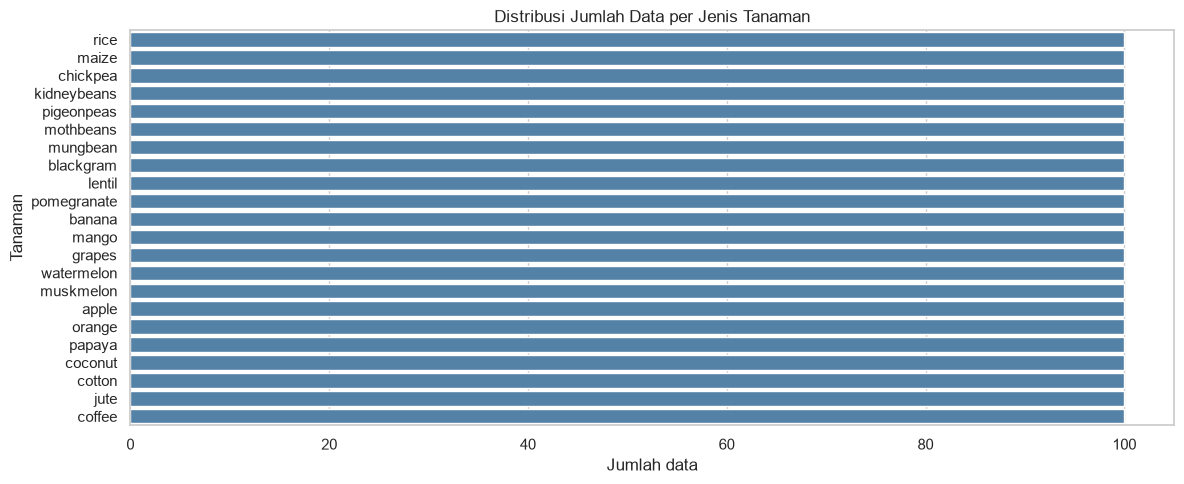

In [13]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, y="label", order=df["label"].value_counts().index, color="steelblue")
plt.title("Distribusi Jumlah Data per Jenis Tanaman")
plt.xlabel("Jumlah data")
plt.ylabel("Tanaman")
plt.tight_layout()
plt.show()

### 3.2 Missing Value dan Duplikat
Data yang hilang atau duplikat dapat memengaruhi kualitas model, jadi perlu dicek lebih dulu.


In [14]:
print("Missing value per kolom:")
print(df.isnull().sum())
print("\nJumlah data duplikat:", df.duplicated().sum())

Missing value per kolom:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Jumlah data duplikat: 0


### 3.3 Statistik Deskriptif
Ringkasan statistik (rata-rata, standar deviasi, min, max, kuartil) untuk setiap fitur numerik. Perhatikan perbedaan skala antar fitur, misalnya `rainfall` bernilai ratusan sedangkan `ph` hanya sekitar 3-10. Ini alasan sebagian model nanti memakai scaling.

In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


### 3.4 Distribusi Kelas Target
Mengecek apakah jumlah data tiap tanaman seimbang. Dataset yang seimbang tidak memerlukan teknik penanganan imbalance seperti SMOTE.

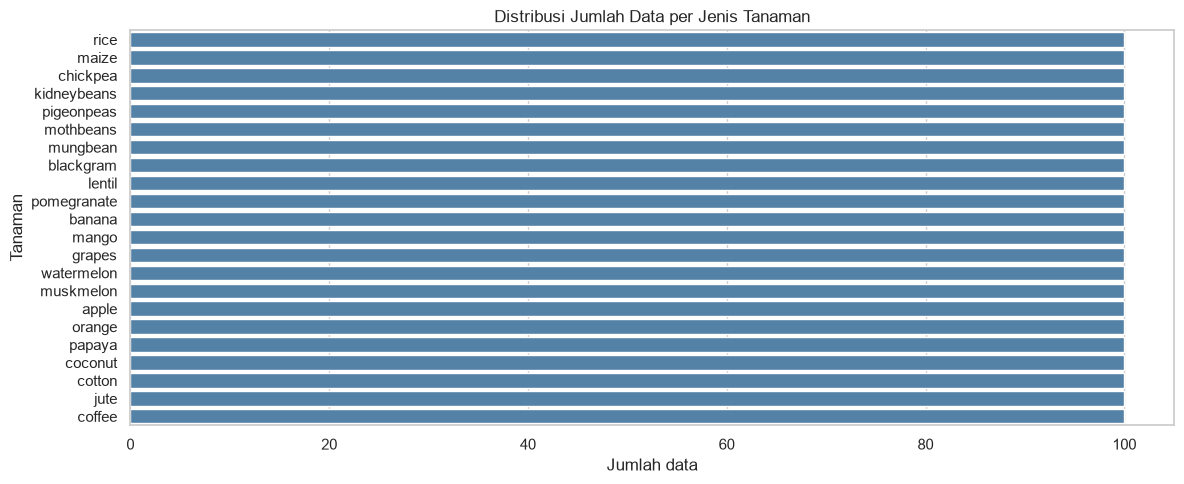

In [16]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, y="label", order=df["label"].value_counts().index, color="steelblue")
plt.title("Distribusi Jumlah Data per Jenis Tanaman")
plt.xlabel("Jumlah data")
plt.ylabel("Tanaman")
plt.tight_layout()
plt.show()

### 3.5 Distribusi Fitur
Histogram dengan kurva KDE untuk melihat sebaran nilai tiap fitur (simetris atau miring, rentang nilai, dan sebagainya).

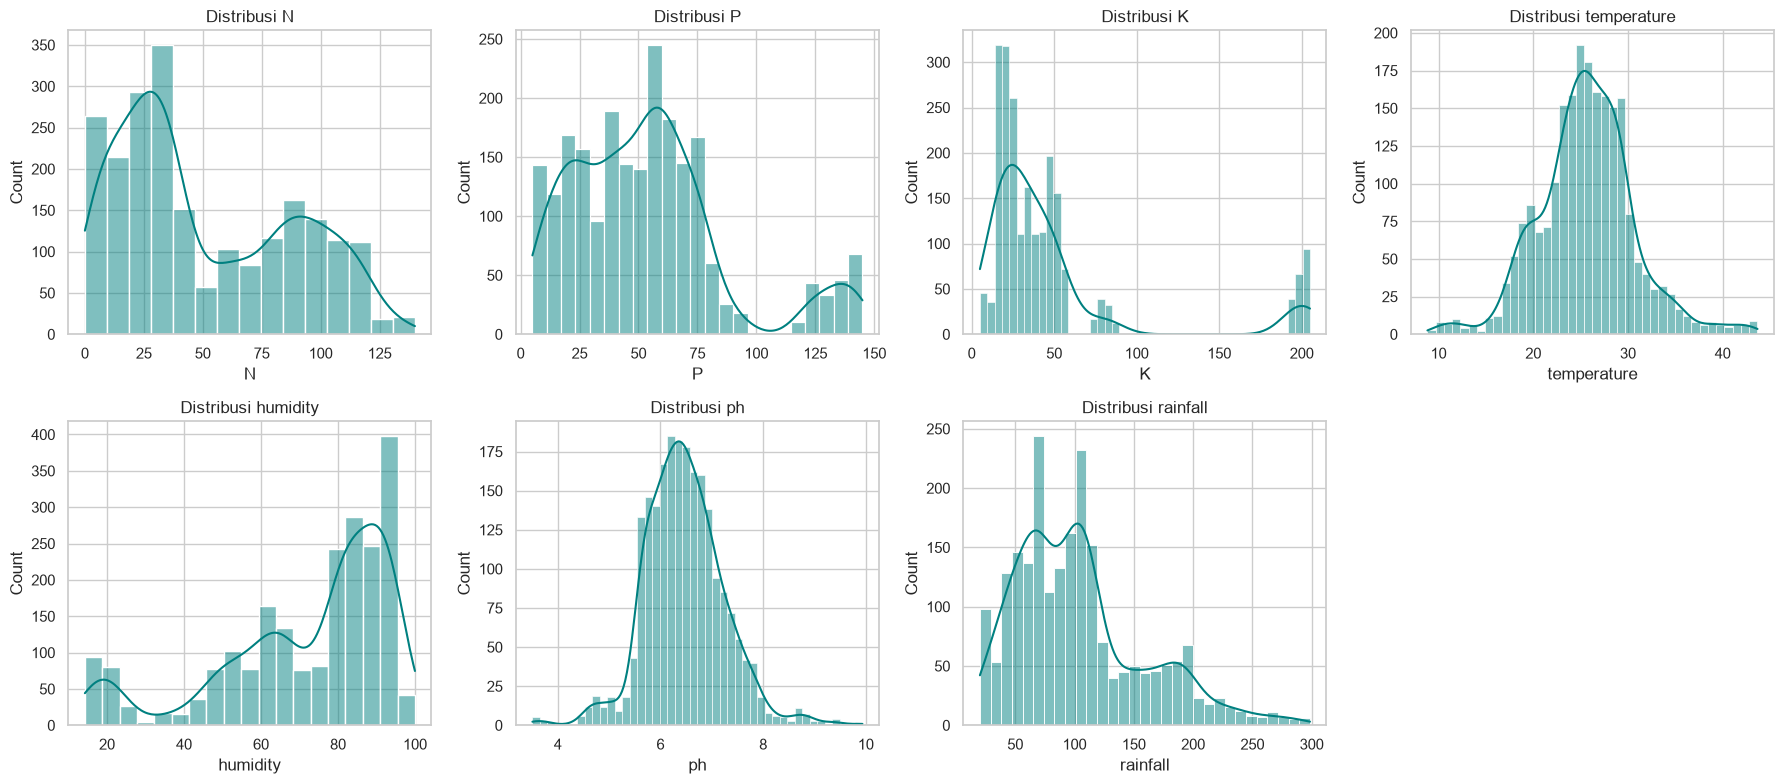

In [17]:
fitur = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, kol in enumerate(fitur):
    sns.histplot(df[kol], kde=True, ax=axes[i], color="teal")
    axes[i].set_title(f"Distribusi {kol}")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

### 3.6 Deteksi Outlier dengan Boxplot
Titik di luar "kumis" boxplot adalah kandidat outlier. Pada dataset ini outlier tidak dihapus karena nilainya masih masuk akal secara agronomi (misalnya tanaman tertentu memang butuh curah hujan atau kalium sangat tinggi), dan model berbasis pohon tahan terhadap outlier.

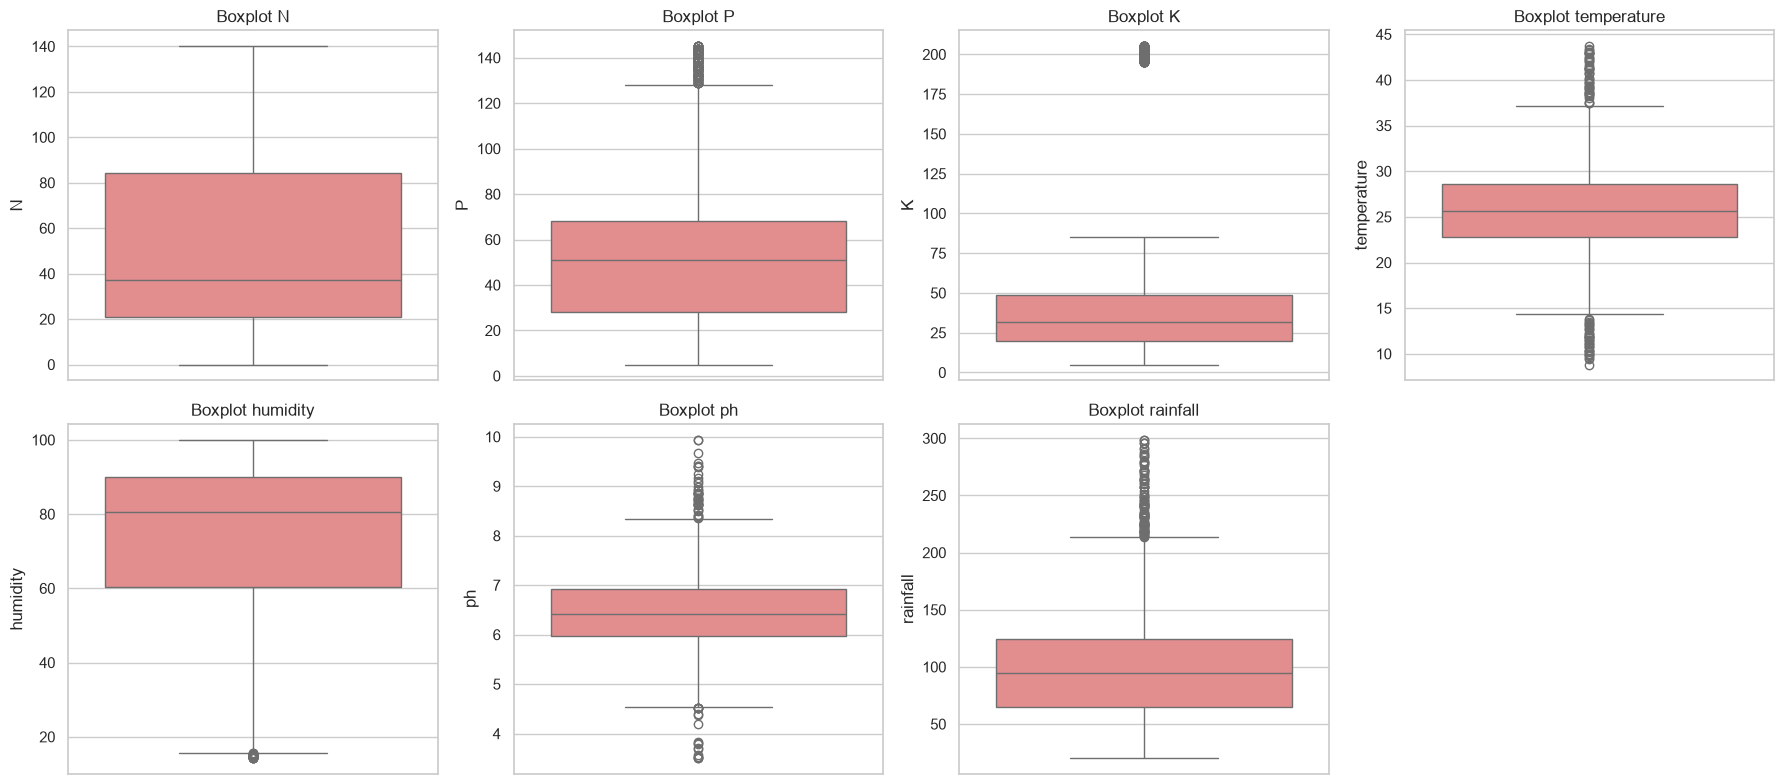

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, kol in enumerate(fitur):
    sns.boxplot(y=df[kol], ax=axes[i], color="lightcoral")
    axes[i].set_title(f"Boxplot {kol}")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

### 3.7 Korelasi Antar Fitur
Heatmap korelasi Pearson. Korelasi tinggi antar fitur (mendekati 1 atau -1) menandakan informasi yang tumpang tindih. Perhatikan pasangan `P` dan `K` yang korelasinya relatif tinggi.

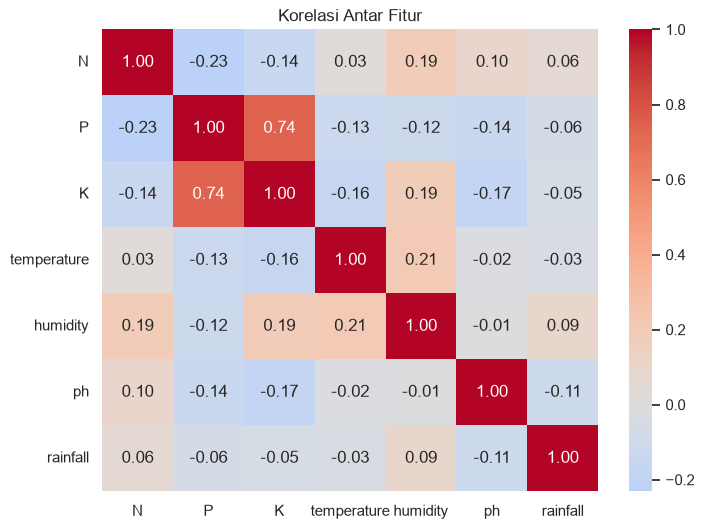

In [19]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[fitur].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi Antar Fitur")
plt.show()

### 3.8 Profil Lingkungan per Tanaman
Heatmap rata-rata tiap fitur untuk setiap tanaman. Warna dinormalisasi per kolom (0-1) agar fitur berskala besar tidak mendominasi, sedangkan angka di dalam sel adalah rata-rata aslinya. Dari sini terlihat tiap tanaman punya "profil" kondisi yang berbeda, yang menjadi dasar bagi model untuk membedakannya.

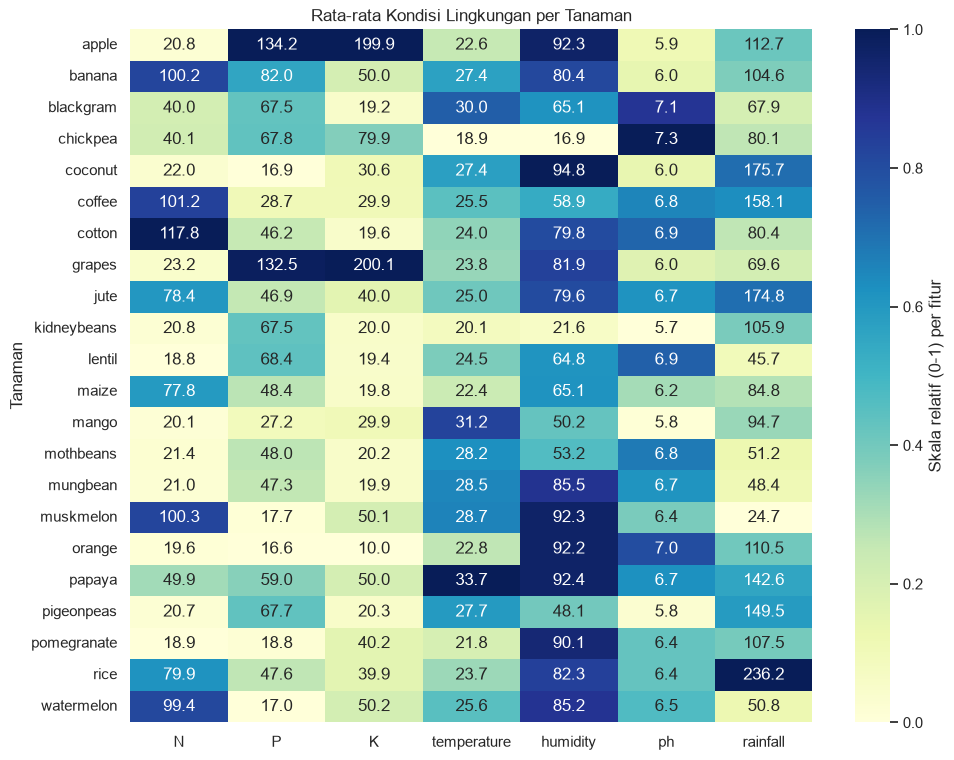

In [20]:
rata = df.groupby("label")[fitur].mean()
rata_norm = (rata - rata.min()) / (rata.max() - rata.min())

plt.figure(figsize=(11, 9))
sns.heatmap(rata_norm, annot=rata.round(1), fmt="", cmap="YlGnBu",
            cbar_kws={"label": "Skala relatif (0-1) per fitur"})
plt.title("Rata-rata Kondisi Lingkungan per Tanaman")
plt.ylabel("Tanaman")
plt.show()

## 4. Preprocessing

### 4.1 Pemisahan Fitur dan Target + Label Encoding
`X` berisi fitur input, `y` berisi nama tanaman. Karena algoritma ML bekerja dengan angka, nama tanaman diubah menjadi angka 0-21 memakai `LabelEncoder`. Encoder disimpan agar hasil prediksi bisa diubah kembali menjadi nama tanaman.

In [21]:
X = df[fitur]
y = df["label"]

le = LabelEncoder()
y_enc = le.fit_transform(y)

print("Jumlah kelas:", len(le.classes_))
print("Kelas:", list(le.classes_))

Jumlah kelas: 22
Kelas: ['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']


### 4.2 Split Data Latih dan Uji
Data dibagi 80% untuk latih dan 20% untuk uji. Parameter `stratify=y_enc` memastikan proporsi tiap tanaman sama di kedua bagian. Data uji **tidak boleh disentuh** selama pelatihan agar evaluasi akhir jujur.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, random_state=RANDOM_STATE, stratify=y_enc
)

print("Data latih:", X_train.shape)
print("Data uji  :", X_test.shape)

Data latih: (1760, 7)
Data uji  : (440, 7)


## 5. Pemodelan

### 5.1 Definisi Model
Tujuh algoritma klasifikasi dibandingkan. Model yang sensitif terhadap skala (Logistic Regression, KNN, SVM) dibungkus dalam `Pipeline` bersama `StandardScaler`. Dengan cara ini scaler hanya "belajar" dari data latih di setiap fold cross-validation, sehingga **tidak terjadi data leakage**. Model berbasis pohon dan Naive Bayes tidak memerlukan scaling.

In [23]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier()),
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(random_state=RANDOM_STATE)),
    ]),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

### 5.2 Pelatihan dan Perbandingan Model
Setiap model dievaluasi dengan **Stratified 5-Fold Cross-Validation** pada data latih (`CV Mean` dan `CV Std`), lalu dilatih ulang dan diuji pada data uji (`Test Acc`). Model dibandingkan terutama berdasarkan `CV Mean` karena lebih stabil daripada satu kali split. Proses ini bisa memakan waktu beberapa saat, terutama Gradient Boosting.

In [24]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
hasil = []

for nama, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=skf, scoring="accuracy")
    model.fit(X_train, y_train)
    acc_test = accuracy_score(y_test, model.predict(X_test))
    hasil.append({
        "Model": nama,
        "CV Mean": cv_scores.mean(),
        "CV Std": cv_scores.std(),
        "Test Acc": acc_test,
    })

hasil_df = pd.DataFrame(hasil).sort_values("CV Mean", ascending=False).reset_index(drop=True)
hasil_df

,Model,CV Mean,CV Std,Test Acc
0,Naive Bayes,0.994886,0.004175,0.995455
1,Random Forest,0.993750,0.006067,0.995455
2,Gradient Boosting,0.986932,0.003409,0.988636
3,Decision Tree,0.985227,0.006818,0.979545
4,SVM,0.978977,0.010259,0.984091
5,Logistic Regression,0.968182,0.006577,0.972727
6,KNN,0.965341,0.012106,0.979545


### 5.3 Visualisasi Perbandingan Model
Diagram batang akurasi cross-validation tiap model. Sumbu-x dipotong mulai 0.90 agar perbedaan kecil antar model terlihat jelas.

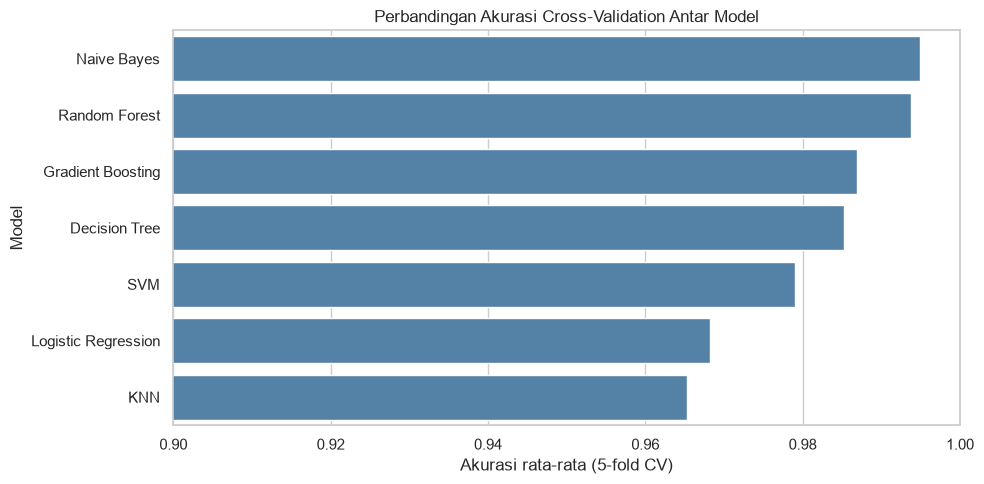

In [25]:
plt.figure(figsize=(10, 5))
sns.barplot(data=hasil_df, x="CV Mean", y="Model", color="steelblue")
plt.xlim(0.90, 1.0)
plt.title("Perbandingan Akurasi Cross-Validation Antar Model")
plt.xlabel("Akurasi rata-rata (5-fold CV)")
plt.tight_layout()
plt.show()

## 6. Hyperparameter Tuning

Pada pengujian saya, Naive Bayes dan Random Forest berada di posisi teratas dengan selisih sangat tipis. **Random Forest** dipilih untuk di-tuning karena memiliki banyak hyperparameter, menyediakan *feature importance*, dan umumnya lebih tangguh pada data nyata. `GridSearchCV` mencoba semua kombinasi parameter dengan cross-validation pada data latih.

In [26]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Parameter terbaik   :", grid.best_params_)
print("Akurasi CV terbaik  :", round(grid.best_score_, 4))

model_final = grid.best_estimator_

Parameter terbaik   : {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
Akurasi CV terbaik  : 0.996


## 7. Evaluasi Model Akhir

### 7.1 Akurasi dan Classification Report
Model terbaik diuji **sekali** pada data uji yang belum pernah dilihat. `precision` menunjukkan ketepatan prediksi, `recall` menunjukkan seberapa banyak data kelas tersebut yang berhasil ditemukan, dan `f1-score` adalah gabungan keduanya.

In [27]:
y_pred = model_final.predict(X_test)

print("Akurasi data uji:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=le.classes_))

Akurasi data uji: 0.9955

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
 

### 7.2 Confusion Matrix
Diagonal menunjukkan prediksi yang benar. Sel di luar diagonal menunjukkan kesalahan: baris adalah kelas sebenarnya, kolom adalah kelas yang diprediksi. Dari sini terlihat tanaman mana yang paling sering tertukar.

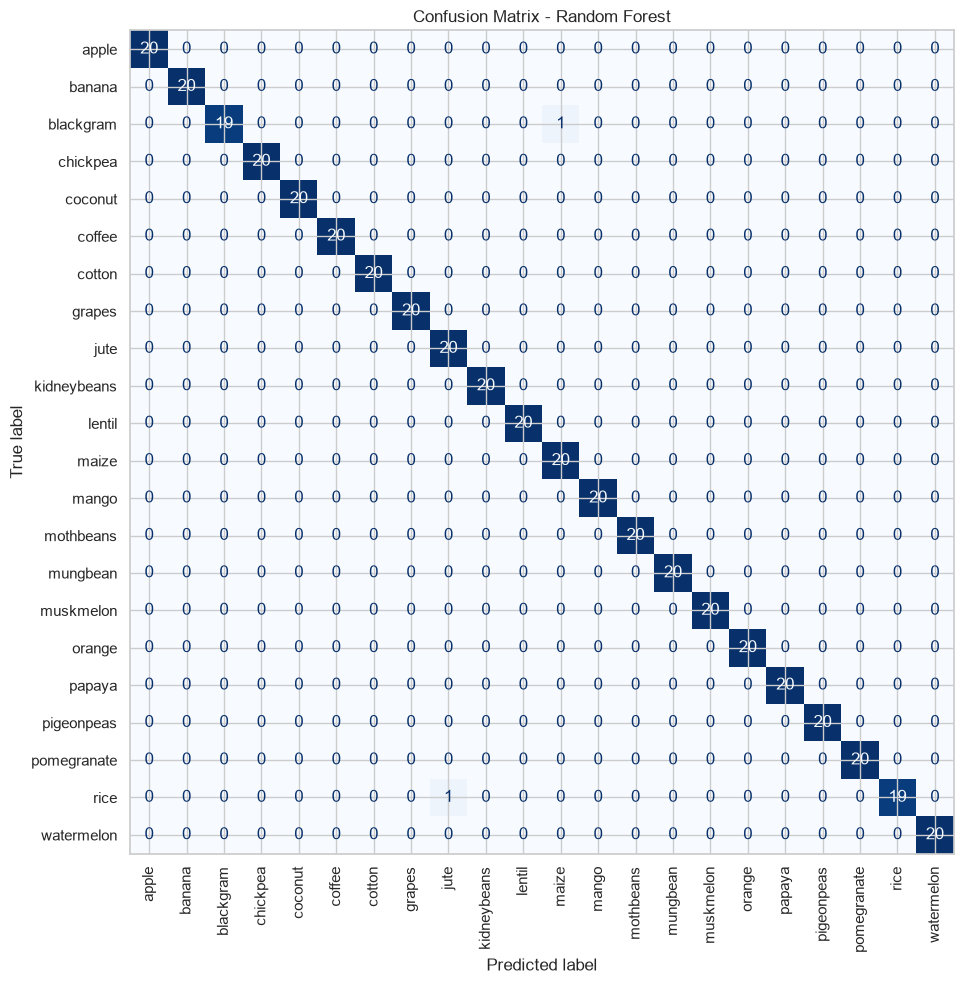

In [28]:
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=le.classes_,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
    colorbar=False,
)
plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()

### 7.3 Feature Importance
Menunjukkan seberapa besar kontribusi tiap fitur dalam keputusan Random Forest. Fitur dengan nilai lebih tinggi lebih berpengaruh dalam membedakan jenis tanaman.

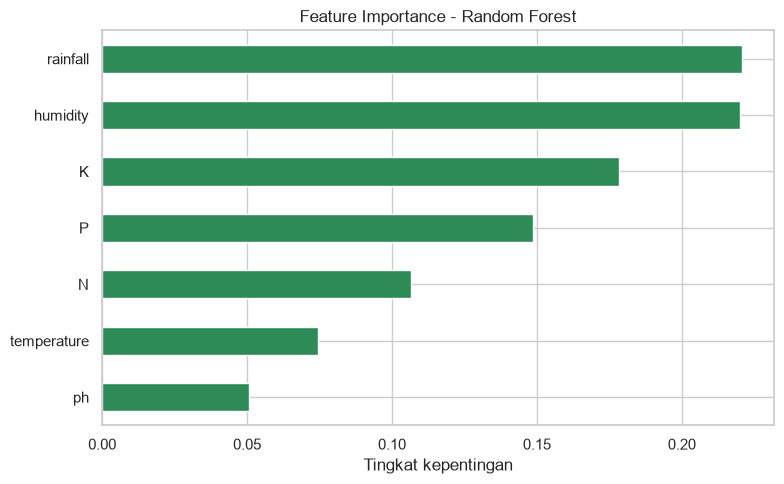

In [29]:
importance = pd.Series(model_final.feature_importances_, index=fitur).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="seagreen")
plt.title("Feature Importance - Random Forest")
plt.xlabel("Tingkat kepentingan")
plt.tight_layout()
plt.show()

## 8. Prediksi Data Baru

Contoh penggunaan model: masukkan kondisi tanah dan cuaca, lalu model memberi rekomendasi tanaman beserta 3 kemungkinan teratas dan probabilitasnya. **Ubah nilai pada dictionary** sesuai kondisi lahan yang ingin diuji.

In [30]:
data_baru = pd.DataFrame([{
    "N": 90, "P": 42, "K": 43,
    "temperature": 20.9, "humidity": 82.0,
    "ph": 6.5, "rainfall": 202.9,
}])

pred = model_final.predict(data_baru)
print("Rekomendasi tanaman:", le.inverse_transform(pred)[0])

proba = model_final.predict_proba(data_baru)[0]
top3 = np.argsort(proba)[::-1][:3]

print("\nTop 3 kemungkinan:")
for i in top3:
    print(f"- {le.classes_[i]:<12} {proba[i] * 100:.2f}%")

Rekomendasi tanaman: rice

Top 3 kemungkinan:
- rice         90.78%
- jute         8.52%
- papaya       0.69%


## 9. Simpan Model

Model dan label encoder disimpan ke file `.pkl` agar bisa dipakai kembali (misalnya di aplikasi web) tanpa melatih ulang. Untuk memuatnya: `joblib.load("model_crop_rf.pkl")`.

In [31]:
joblib.dump(model_final, "model_crop_rf.pkl")
joblib.dump(le, "label_encoder.pkl")
print("Model dan label encoder berhasil disimpan.")

Model dan label encoder berhasil disimpan.


## 10. Kesimpulan

- Dataset terdiri dari 2.200 data, 7 fitur numerik, dan 22 kelas tanaman yang seimbang, tanpa missing value maupun duplikat.
- Tujuh algoritma dibandingkan dengan 5-fold cross-validation; model berbasis probabilistik dan ensemble (Naive Bayes, Random Forest) memberi hasil terbaik.
- Random Forest hasil tuning mencapai akurasi sekitar **99%** pada data uji. *(Sesuaikan dengan angka dari hasil Anda.)*
- Fitur yang paling berpengaruh: **rainfall, humidity, dan K**. *(Sesuaikan dengan grafik feature importance Anda.)*

**Catatan:** Dataset ini sangat bersih dan antar-kelasnya mudah dipisahkan, sehingga akurasi tinggi tidak otomatis berarti model akan sama baiknya pada data lapangan yang lebih beragam.